## At the close of day t, predict the volatility of day t+1, using only information from day t and earlier.” Every check below serves that sentence. The part to watch is “only information from t and earlier”

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

# a notebook in notebooks/ runs from that folder, hence "../data"
path = "../data/realized_variance_stocks_20261030/realized_variance_stocks_20261030.csv"
stocks = pd.read_csv(path, parse_dates=["date"])
stocks.head()

Matplotlib is building the font cache; this may take a moment.


,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,medrv5,medrv5_ss,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.47,107.350,0.000512,...,0.000307,0.000291,0.000269,0.000365,0.000310,0.000291,1.636997e-07,9.045224e-07,5.234818e-07,"DOW30, S&P100"
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.65,105.410,0.000331,...,0.000342,0.000221,0.000277,0.000365,0.000261,0.000220,1.362068e-07,2.405967e-07,1.006578e-07,"DOW30, S&P100"
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.42,104.630,0.000250,...,0.000525,0.000416,0.000364,0.000576,0.000410,0.000341,2.224424e-07,1.825222e-07,1.929761e-07,"DOW30, S&P100"
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.20,106.695,0.000071,...,0.000186,0.000155,0.000201,0.000188,0.000156,0.000183,7.237007e-08,2.564956e-08,3.986406e-08,"DOW30, S&P100"
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.15,108.700,0.000352,...,0.000137,0.000120,0.000131,0.000134,0.000129,0.000136,8.016973e-08,1.968634e-08,3.549955e-08,"DOW30, S&P100"


In [5]:
print(stocks.shape)
stocks["symbol"].nunique(), stocks["date"].min(), stocks["date"].max()

(119000, 35)


(40, Timestamp('2015-01-02 00:00:00'), Timestamp('2026-10-30 00:00:00'))

In [6]:
stocks.groupby("symbol").size()

symbol
AAPL     2975
ADBE     2975
AMD      2975
AMGN     2975
AMZN     2975
AXP      2975
BA       2975
CAT      2975
CRM      2975
CSCO     2975
CVX      2975
DIS      2975
GE       2975
GOOGL    2975
GS       2975
HD       2975
HON      2975
IBM      2975
JNJ      2975
JPM      2975
KO       2975
MCD      2975
META     2975
MMM      2975
MRK      2975
MSFT     2975
NFLX     2975
NKE      2975
NVDA     2975
ORCL     2975
PG       2975
PM       2975
SHW      2975
TRV      2975
TSLA     2975
UNH      2975
V        2975
VZ       2975
WMT      2975
XOM      2975
dtype: int64

In [7]:
2975*40

119000

In [9]:
stocks.isna().sum()

date           0
symbol         0
asset_type     0
volume         0
trades         0
open_price     0
close_price    0
high_price     0
low_price      0
pr             0
gkr            0
rr5            0
rv1            0
rv5            0
rv5_ss         0
bv1            0
bv5            0
bv5_ss         0
rsp1           0
rsn1           0
rsp5           0
rsn5           0
rsp5_ss        0
rsn5_ss        0
medrv1         0
medrv5         0
medrv5_ss      0
minrv1         0
minrv5         0
minrv5_ss      0
rk             0
rq1            0
rq5            0
rq5_ss         0
index          0
dtype: int64

In [10]:
(stocks["rv5"] <= 0).sum()

np.int64(0)

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,medrv5,medrv5_ss,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index
0,2015-01-02,AAPL,stocks,52510449,286295,111.3973,109.240,111.47,107.350,0.000512,...,0.000307,0.000291,0.000269,0.000365,0.000310,0.000291,1.636997e-07,9.045224e-07,5.234818e-07,"DOW30, S&P100"
1,2015-01-05,AAPL,stocks,60727778,316713,108.2914,106.380,108.65,105.410,0.000331,...,0.000342,0.000221,0.000277,0.000365,0.000261,0.000220,1.362068e-07,2.405967e-07,1.006578e-07,"DOW30, S&P100"
2,2015-01-06,AAPL,stocks,64865433,362762,106.4644,106.300,107.42,104.630,0.000250,...,0.000525,0.000416,0.000364,0.000576,0.000410,0.000341,2.224424e-07,1.825222e-07,1.929761e-07,"DOW30, S&P100"
3,2015-01-07,AAPL,stocks,39052235,220326,107.1898,107.825,108.20,106.695,0.000071,...,0.000186,0.000155,0.000201,0.000188,0.000156,0.000183,7.237007e-08,2.564956e-08,3.986406e-08,"DOW30, S&P100"
4,2015-01-08,AAPL,stocks,57390801,302187,109.3600,111.940,112.15,108.700,0.000352,...,0.000137,0.000120,0.000131,0.000134,0.000129,0.000136,8.016973e-08,1.968634e-08,3.549955e-08,"DOW30, S&P100"


In [13]:
aapl = stocks[stocks["symbol"] == "AAPL"]


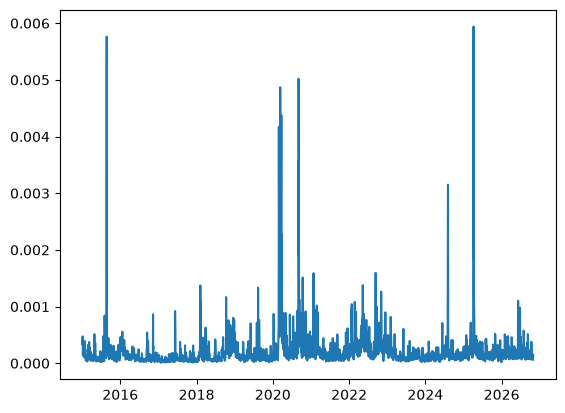

In [17]:
plt.plot(aapl['date'], aapl['rv5'])

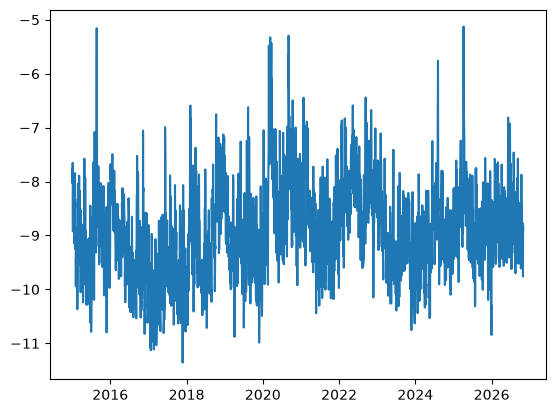

In [18]:
plt.plot(aapl['date'], np.log(aapl['rv5']))

(array([2.85e+03, 9.10e+01, 1.50e+01, 5.00e+00, 3.00e+00, 1.00e+00,
        3.00e+00, 2.00e+00, 2.00e+00, 3.00e+00]),
 array([1.16788517e-05, 6.04560088e-04, 1.19744132e-03, 1.79032256e-03,
        2.38320380e-03, 2.97608503e-03, 3.56896627e-03, 4.16184751e-03,
        4.75472874e-03, 5.34760998e-03, 5.94049122e-03]),
 <BarContainer object of 10 artists>)

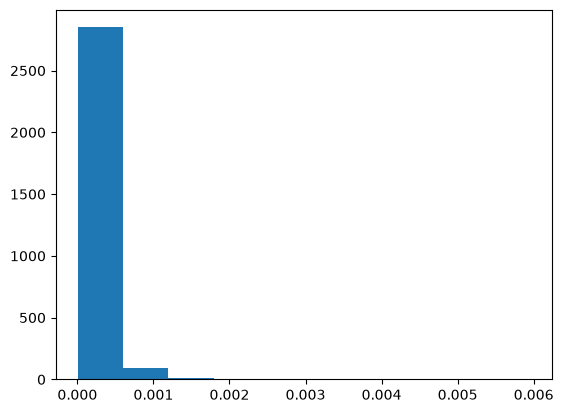

In [19]:
plt.hist(aapl["rv5"])

(array([ 20., 174., 576., 873., 770., 377., 132.,  32.,  11.,  10.]),
 array([-11.3577309 , -10.73455415, -10.11137741,  -9.48820066,
         -8.86502392,  -8.24184717,  -7.61867043,  -6.99549369,
         -6.37231694,  -5.7491402 ,  -5.12596345]),
 <BarContainer object of 10 artists>)

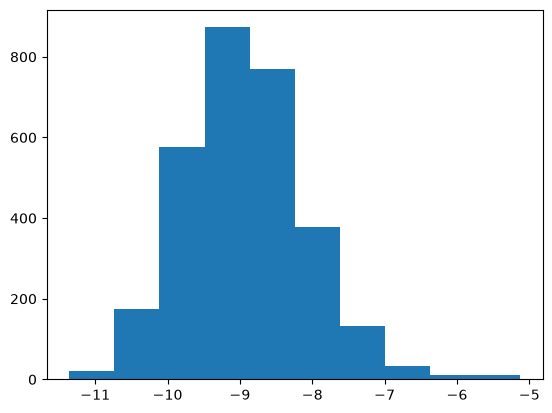

In [20]:
plt.hist(np.log(aapl["rv5"]))

In [21]:
aapl.nlargest(5, "rv5")[["date", "rv5"]]

,date,rv5
2580,2025-04-07,0.005940
2582,2025-04-09,0.005781
161,2015-08-24,0.005762
1429,2020-09-04,0.005021
1306,2020-03-12,0.004870


In [22]:
aapl.nsmallest(5, "rv5")

,date,symbol,asset_type,volume,trades,open_price,close_price,high_price,low_price,pr,...,medrv5,medrv5_ss,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss,index
730,2017-11-24,AAPL,stocks,12732742,62510,175.1000,174.9600,175.5000,174.6401,0.000009,...,0.000007,0.000008,0.000030,0.000009,0.000008,0.000015,1.858693e-09,3.138568e-10,6.171292e-10,"DOW30, S&P100"
518,2017-01-24,AAPL,stocks,22562050,133482,119.5500,120.0100,120.1000,119.5000,0.000009,...,0.000010,0.000010,0.000018,0.000012,0.000012,0.000014,1.039114e-09,1.137763e-09,5.017889e-10,"DOW30, S&P100"
537,2017-02-21,AAPL,stocks,23088985,127569,136.2400,136.6832,136.7500,135.9700,0.000012,...,0.000012,0.000020,0.000031,0.000010,0.000023,0.000022,1.151249e-08,3.162820e-10,1.221412e-09,"DOW30, S&P100"
516,2017-01-20,AAPL,stocks,28684854,147134,120.2000,120.0000,120.4367,119.7300,0.000012,...,0.000013,0.000014,0.000028,0.000016,0.000016,0.000024,2.000129e-09,2.926899e-10,3.033567e-10,"DOW30, S&P100"
555,2017-03-17,AAPL,stocks,42634196,121116,140.9173,140.0000,141.0000,139.8900,0.000023,...,0.000014,0.000016,0.000017,0.000013,0.000016,0.000019,6.172035e-10,4.466022e-10,3.708502e-10,"DOW30, S&P100"


The top 5 are all well-known stress days

2020-03-12: COVID crash.
2015-08-24: the flash crash.
2025-04-07 and 2025-04-09: the tariff turmoil.
2020-09-04: AAPL-heavy tech selloff, which I’d verify against other stocks.

The lowest day is a half-day

2017-11-24 is the day after Thanksgiving. Its volume is 12.7M and its trades are 62k, far below the other lowest days. That confirms the calendar effect.
The other four lowest days (Jan–Mar 2017) are just quiet days with normal volume. They aren’t anomalies.

In [24]:
wide = stocks.pivot(index="date", columns="symbol", values="rv5")
ratio = wide / wide.median()
ratio.median(axis=1).nlargest(10)

date
2020-03-16    45.568333
2020-03-18    43.623002
2020-03-12    41.493460
2020-03-19    37.887177
2020-03-23    36.063977
2020-03-13    35.999411
2020-03-17    34.024022
2025-04-07    31.491251
2015-08-24    26.778452
2020-03-20    25.462264
dtype: float64

In [25]:
ratio.loc["2020-09-04"].sort_values().tail(10)

symbol
META      7.163054
V         7.624065
GOOGL     7.961640
NFLX      8.135342
ADBE     10.426579
MSFT     13.816139
AMZN     14.757618
NVDA     17.353256
TSLA     21.809764
AAPL     39.254739
Name: 2020-09-04 00:00:00, dtype: float64

volatility has a market factor and a sector factor,

In [26]:
(ratio.loc["2023-01-24"] > 10).sum()

np.int64(8)

In [27]:
bad = ratio.loc["2023-01-24"].sort_values().tail(8).index
sub = stocks[stocks["symbol"].isin(bad) & stocks["date"].between("2023-01-20", "2023-01-27")]
sub[["date", "symbol", "close_price", "high_price", "low_price", "rv5", "pr"]].sort_values(["symbol", "date"])

,date,symbol,close_price,high_price,low_price,rv5,pr
64501,2023-01-20,MCD,268.5800,268.6500,262.8200,0.000087,0.000174
64502,2023-01-23,MCD,269.2900,271.2000,267.7370,0.000069,0.000060
64503,2023-01-24,MCD,269.5600,270.1800,236.4200,0.005371,0.006426
64504,2023-01-25,MCD,273.0000,273.0900,268.6100,0.000085,0.000099
64505,2023-01-26,MCD,274.7200,274.7700,271.6300,0.000088,0.000048
64506,2023-01-27,MCD,272.4600,275.3600,271.9600,0.000060,0.000056
70451,2023-01-20,MMM,120.6500,120.8000,116.7600,0.000265,0.000417
70452,2023-01-23,MMM,122.5800,123.9000,120.4100,0.000107,0.000294
70453,2023-01-24,MMM,115.1616,119.9258,114.5047,0.002201,0.000772
70454,2023-01-25,MMM,112.9300,116.2405,112.7500,0.000270,0.000335


In [29]:
sub[["date", "symbol", "close_price", "high_price", "low_price", "rv5", "minrv5", 'medrv5']].sort_values(["symbol", "date"])

,date,symbol,close_price,high_price,low_price,rv5,minrv5,medrv5
64501,2023-01-20,MCD,268.5800,268.6500,262.8200,0.000087,0.000077,0.000071
64502,2023-01-23,MCD,269.2900,271.2000,267.7370,0.000069,0.000065,0.000068
64503,2023-01-24,MCD,269.5600,270.1800,236.4200,0.005371,0.000154,0.000149
64504,2023-01-25,MCD,273.0000,273.0900,268.6100,0.000085,0.000089,0.000090
64505,2023-01-26,MCD,274.7200,274.7700,271.6300,0.000088,0.000077,0.000069
64506,2023-01-27,MCD,272.4600,275.3600,271.9600,0.000060,0.000072,0.000062
70451,2023-01-20,MMM,120.6500,120.8000,116.7600,0.000265,0.000144,0.000134
70452,2023-01-23,MMM,122.5800,123.9000,120.4100,0.000107,0.000113,0.000096
70453,2023-01-24,MMM,115.1616,119.9258,114.5047,0.002201,0.002985,0.002773
70454,2023-01-25,MMM,112.9300,116.2405,112.7500,0.000270,0.000127,0.000147


a day is suspicious if the market looked wild, but the price didn’t actually go anywhere, and the next day was normal again.

In [30]:
stocks = stocks.sort_values(["symbol", "date"])

# 1. how wild was the day compared with that stock's normal day?
stocks["rel"] = stocks["rv5"] / stocks.groupby("symbol")["rv5"].transform("median")

# 2. how much did the price really move, close to close?
stocks["move"] = stocks.groupby("symbol")["close_price"].pct_change().abs()

# 3. was the NEXT day back to normal?
stocks["rel_next"] = stocks.groupby("symbol")["rel"].shift(-1)

flag = (stocks["rel"] > 20) & (stocks["move"] < 0.03) & (stocks["rel_next"] < 3)
print(flag.sum())
stocks[flag][["date", "symbol", "rel", "move", "rel_next"]]

14


,date,symbol,rel,move,rel_next
16389,2021-01-07,AXP,27.231539,0.011377,2.089774
23884,2015-05-05,CRM,21.670096,0.016061,2.969943
32613,2026-05-22,CVX,23.023874,0.002199,2.065672
64503,2023-01-24,MCD,73.509972,0.001003,1.164880
68586,2015-08-24,MMM,24.060051,0.024703,2.899013
76466,2023-04-25,MSFT,23.986096,0.029338,2.003571
82353,2023-01-24,NKE,34.558472,0.011380,0.931020
89687,2016-09-27,PG,41.709132,0.018441,1.791862
92872,2017-07-28,PM,26.269589,0.002708,1.534148
92996,2018-01-25,PM,23.906253,0.028119,1.649139


In [34]:
cols = ["date", "symbol", "close_price", "high_price", "low_price", "rv5", "minrv5"]
out = stocks[flag][cols].copy()
out["rv5/minrv5"] = out["rv5"] / out["minrv5"]
out


,date,symbol,close_price,high_price,low_price,rv5,minrv5,rv5/minrv5
16389,2021-01-07,AXP,121.6600,125.7072,117.3500,0.003201,0.002728,1.173073
23884,2015-05-05,CRM,72.7500,76.1800,71.0000,0.004357,0.001573,2.769297
32613,2026-05-22,CVX,191.4300,197.8223,189.7700,0.002783,0.003802,0.731904
64503,2023-01-24,MCD,269.5600,270.1800,236.4200,0.005371,0.000154,34.901839
68586,2015-08-24,MMM,138.5800,142.1000,134.0000,0.002650,0.003683,0.719383
76466,2023-04-25,MSFT,290.1600,291.2600,275.2200,0.002806,0.000167,16.808119
82353,2023-01-24,NKE,126.8300,128.0050,112.3600,0.004705,0.000831,5.661102
89687,2016-09-27,PG,89.4700,89.7300,87.5400,0.002919,0.003301,0.884168
92872,2017-07-28,PM,118.5100,118.9200,109.3100,0.002590,0.003460,0.748606
92996,2018-01-25,PM,107.4900,111.2500,103.0200,0.002357,0.002011,1.171818


In [35]:
stocks.loc[(stocks.symbol == "PG") & (stocks.date == "2016-09-27"), ["rv5", "pr", "rr5", "rk"]]

,rv5,pr,rr5,rk
89687,0.002919,0.00022,0.003873,0.000298


lag 1: 0.7099564286953932  lag 5: 0.49631952100863586  lag 22: 0.3378989722860145  lag 60: 0.16676125470740408


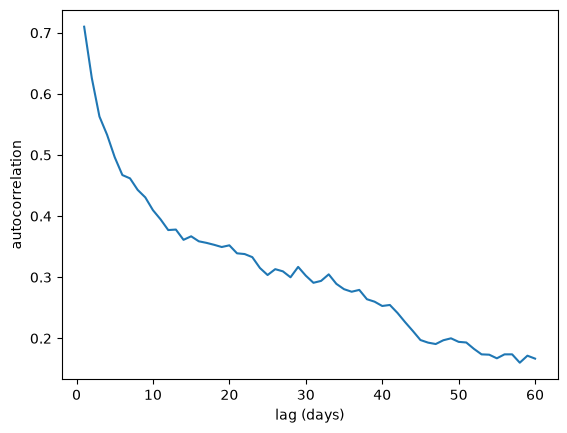

In [36]:
aapl = stocks[stocks["symbol"] == "AAPL"]
y = np.log(aapl["rv5"])

acf = [y.autocorr(lag=k) for k in range(1, 61)]

plt.plot(range(1, 61), acf)
plt.xlabel("lag (days)")
plt.ylabel("autocorrelation")

print("lag 1:", acf[0], " lag 5:", acf[4], " lag 22:", acf[21], " lag 60:", acf[59])

In [37]:
logw = np.log(wide)
acf_all = pd.DataFrame({k: [logw[c].autocorr(lag=k) for c in logw.columns] for k in [1, 5, 22]}, index=logw.columns)
acf_all.describe()

,1,5,22
count,40.000000,40.000000,40.000000
mean,0.704107,0.529120,0.364764
std,0.043207,0.062440,0.072817
min,0.629772,0.407161,0.230058
25%,0.670786,0.481506,0.324347
50%,0.699982,0.521490,0.348343
75%,0.735392,0.570599,0.414200
max,0.797746,0.685243,0.552847
